# Risk Prediction Overview

## Prepare the environment

In [1]:
# 1. Enable Auto-reloading
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import matplotlib.pyplot as plt

# Add the project root to Python path
project_root = Path.cwd().parent  # Goes up one level from notebooks/
sys.path.insert(0, str(project_root))

# 2. Import your heavy logic from your Python file
from core.gnn_layer.risk_predict import (
    fetch_graph_from_neo4j, 
    RiskEscalationGNN, 
    train_model,
    graph_edge_oversample, 
    evaluate_with_kfold,
    generate_threat_report
)

from core.kg_sna_layer.graph_builder import(
    calculate_strict_fold_topology,
    wipe_sna_metrics
)

print("Environment linked and modules loaded successfully!")

import torch
import random
import numpy as np

# Lock the random seed for 100% reproducibility
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

print("Random seed set!")

c:\Users\dhara\anaconda3\envs\sna_oms_thesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment linked and modules loaded successfully!
Random seed set!


In [ ]:
wipe_sna_metrics(graph_base.URL, graph_base.USER, graph_base.PASS)

# Phase 1: Raw Data Fetching and class imabalance

### Class Imbalance

Step 1: Fetching raw metadata distributions from Neo4j...


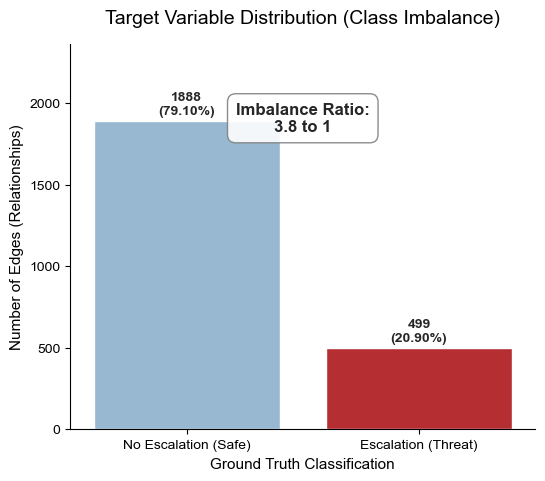

In [2]:
import pandas as pd
from neo4j import GraphDatabase
from core.config import graph_base
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

def fetch_raw_class_counts(uri, user, password):
    """
    Fetches the raw count of positive (escalation) vs negative edges 
    by reading the semantic relationship types, ignoring SNA meta-edges.
    """
    query = """
    MATCH ()-[r]->()
    // 1. Filter out the meta-edges generated by the SNA graph_builder
    WHERE type(r) <> 'SNA_TIE_STRENGTH'
    RETURN 
        // 2. Classify based on your actual OMS ontology from schemas.py
        CASE WHEN type(r) IN ['ASSAULTS', 'THREATENS', 'SELF_HARM'] THEN 'Escalation (Class 1)' 
             ELSE 'Baseline (Class 0)' END as Class,
        count(r) as Count
    """
    
    with GraphDatabase.driver(uri, auth=(user, password)) as driver:
        with driver.session() as session:
            result = session.run(query)
            df = pd.DataFrame([dict(record) for record in result])
            
    if df.empty:
        df = pd.DataFrame({'Class': ['Baseline (Class 0)', 'Escalation (Class 1)'], 'Count': [0, 0]})
    return df

def plot_class_imbalance(df_counts):
    """
    Generates a clean bar chart showing the extreme class imbalance.
    """
    fig, ax = plt.subplots(figsize=(6, 5))
    
    sns.set_theme(style="whitegrid")
    # Custom functional design styling
    #['Baseline (Class 0)', 'Escalation (Class 1)']
    sns.barplot(x=['No Escalation (Safe)', 'Escalation (Threat)'], y='Count', data=df_counts, palette=['#8ebad9', '#cb181d'], ax=ax, hue='Class', legend=False)
    
    # Annotate bars with exact counts and percentages
    total = df_counts['Count'].sum()
    for p in ax.patches:
        height = p.get_height()
        percentage = (height / total) * 100 if total > 0 else 0
        ax.text(p.get_x() + p.get_width()/2., height + (total * 0.01),
                f'{int(height)}\n({percentage:.2f}%)',
                ha="center", va="bottom", fontsize=10, fontweight='bold')
    
    # Safely extract the counts based on the exact string labels from our Cypher query
    safe_count = df_counts.loc[df_counts['Class'] == 'Baseline (Class 0)', 'Count'].sum()
    threat_count = df_counts.loc[df_counts['Class'] == 'Escalation (Class 1)', 'Count'].sum()
    
    imbalance_ratio = safe_count / threat_count if threat_count > 0 else 0
    textstr = f'Imbalance Ratio:\n{imbalance_ratio:.1f} to 1'
    
    # Add the text box in the upper center of the plot
    ax.text(0.5, 0.85, textstr, transform=ax.transAxes, fontsize=12,
             verticalalignment='top', horizontalalignment='center', fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.9))
    
    # Dynamically scale the y-axis so the text box doesn't overlap the bars
    max_count = df_counts['Count'].max()
    ax.set_ylim(0, max_count * 1.25)
                
    ax.set_title("Target Variable Distribution (Class Imbalance)", fontsize=14, pad=15)
    ax.set_xlabel("Ground Truth Classification", fontsize=11)
    ax.set_ylabel("Number of Edges (Relationships)", fontsize=11)

    sns.despine()
    return fig


print("Step 1: Fetching raw metadata distributions from Neo4j...")
df_class = fetch_raw_class_counts(graph_base.URL, graph_base.USER, graph_base.PASS)
# Generate and display Class Imbalance
fig_imbalance = plot_class_imbalance(df_class)
timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
#plt.savefig(f"{timestamp_dist}_class_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

### Taxonomy distribution

Step 2: Rendering Data Quality and Imbalance Visualizations...
✅ Cleaned Data ready for plotting:
   Severity  Frequency                    Category
0       1.0        349  Level 1: NEUTRAL/EMOTIONAL
1       2.0        367    Level 2: VIOLATED_SCALED
2       3.0       1417               Level 3: HATE
3       4.0        254             Level 4: THREAT


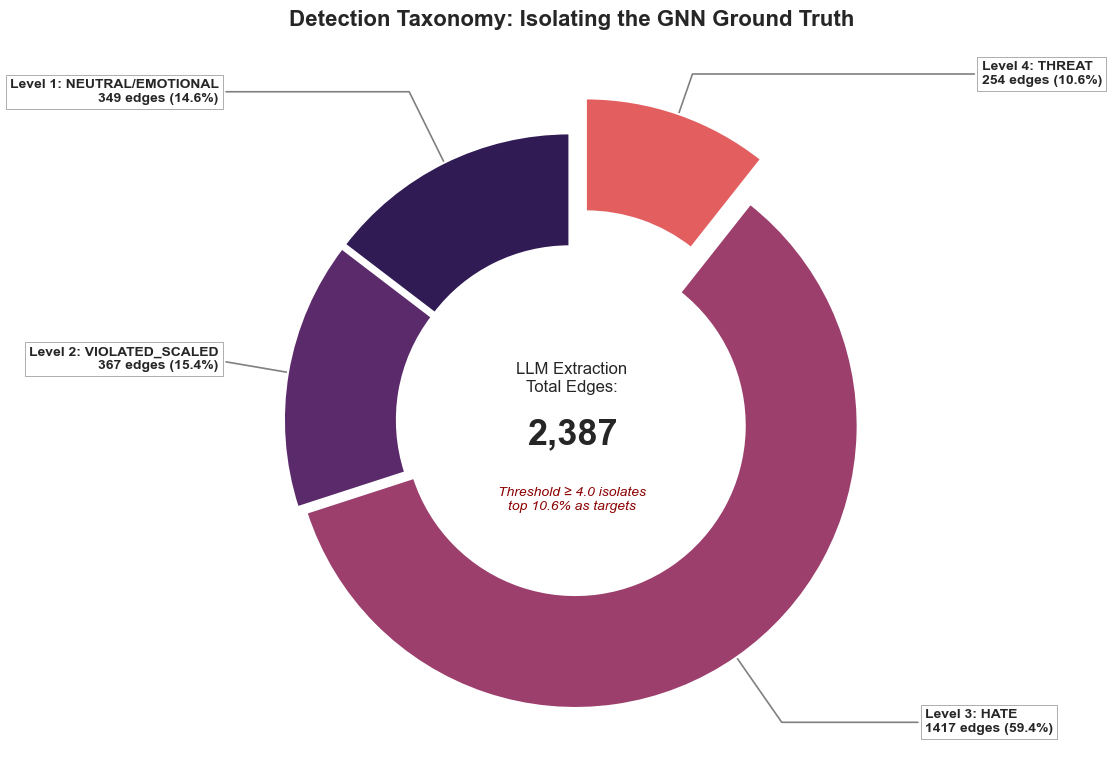

In [3]:
def fetch_taxonomy_distribution(uri, user, password):
    # 1. We capitalize the aliases directly in Cypher. 
    # Neo4j will hand them to Pandas already perfectly named.
    query = """
    MATCH ()-[r]->()
    WHERE type(r) <> 'SNA_TIE_STRENGTH' AND r.risk_weight IS NOT NULL
    RETURN r.risk_weight AS Severity, count(r) AS Frequency
    """
    
    with GraphDatabase.driver(uri, auth=(user, password)) as driver:
        with driver.session() as session:
            result = session.run(query)
            
            # THE FIX: dict(record) automatically extracts exactly what the query returned.
            # No manual list comprehensions, no KeyErrors.
            df = pd.DataFrame([dict(record) for record in result])
            
    if df.empty:
        print("No taxonomy weights found! Check your database.")
        return df

    # 2. Data Cleaning
    df['Severity'] = pd.to_numeric(df['Severity'], errors='coerce').round(0)
    
    # THE FIX: Named Aggregation. 
    # This explicitly forces Pandas to create a column called 'Frequency' 
    # containing the sum, guaranteeing it does not drop off.
    df = df.groupby('Severity').agg(Frequency=('Frequency', 'sum')).reset_index()

    # 3. Map severity integers to Taxonomy names
    severity_to_name = {
        1.0: "Level 1: NEUTRAL/EMOTIONAL",
        2.0: "Level 2: VIOLATED_SCALED",
        3.0: "Level 3: HATE",
        4.0: "Level 4: THREAT",
        5.0: "Level 5: EXTREMIST/RADICALISM"
    }
    df['Category'] = df['Severity'].map(severity_to_name)
    
    # 4. Drop outliers and sort sequentially
    df = df.dropna(subset=['Category']).sort_values('Severity')

    print("✅ Cleaned Data ready for plotting:")
    print(df) 

    return df
    
def plot_taxonomy_donut(df):
    """
    Generates a true donut chart with external leader lines, custom severity colors,
    and central methodology annotations.
    """
    if df.empty:
        return None
        
    fig, ax = plt.subplots(figsize=(11, 8), subplot_kw=dict(aspect="equal"))
    
    labels = df['Category'].tolist()
    sizes = df['Frequency'].tolist()
    severities = df['Severity'].tolist()
    total_edges = sum(sizes)
    
    # 1. Map your custom color palette strictly to the severity level
    color_map = {
        1.0: '#311b54', 
        2.0: '#5b2a6b', 
        3.0: '#9c3f6c', 
        4.0: '#e35f5f', 
        5.0: '#fca15d'
    }
    colors = [color_map[sev] for sev in severities]
    
    # 2. Dynamic Explode: Pull high-severity targets out further
    explode = [0.15 if sev >= 4.0 else 0.02 for sev in severities]
    
    # 3. Create the base true donut
    wedges, _ = ax.pie(
        sizes, 
        explode=explode, 
        colors=colors,
        startangle=90, 
        wedgeprops=dict(width=0.4, edgecolor='white', linewidth=1.5)
    )
    
    # 4. Configure external leader lines
    bbox_props = dict(boxstyle="square,pad=0.3", fc="white", ec="gray", lw=0.5, alpha=0.9)
    kw = dict(arrowprops=dict(arrowstyle="-", color="gray", lw=1.2),
              bbox=bbox_props, zorder=0, va="center", fontsize=10, fontweight='bold')

    for i, p in enumerate(wedges):
        ang = (p.theta2 - p.theta1) / 2. + p.theta1
        y = np.sin(np.deg2rad(ang))
        x = np.cos(np.deg2rad(ang))
        
        horizontalalignment = {-1: "right", 1: "left"}[int(np.sign(x))]
        connectionstyle = f"angle,angleA=0,angleB={ang}"
        kw["arrowprops"].update({"connectionstyle": connectionstyle})
        
        # Combine name, count, and percentage in the external box
        percentage = (sizes[i] / total_edges) * 100
        label_text = f"{labels[i]}\n{sizes[i]} edges ({percentage:.1f}%)"
        
        # Dynamic line extension so the text box doesn't hit exploded slices
        offset = 1.45 if severities[i] >= 4.0 else 1.25
        ax.annotate(label_text, xy=(x, y), xytext=(offset*np.sign(x), 1.3*y),
                    horizontalalignment=horizontalalignment, **kw)
    
    # 5. Central Text Annotations (Methodology Storytelling)
    threat_edges = df[df['Severity'] >= 4.0]['Frequency'].sum()
    threat_pct = (threat_edges / total_edges) * 100 if total_edges > 0 else 0
    
    ax.text(0, 0.15, "LLM Extraction\nTotal Edges:", ha='center', va='center', fontsize=12)
    ax.text(0, -0.05, f"{total_edges:,}", ha='center', va='center', fontsize=26, fontweight='bold')
    ax.text(0, -0.28, f"Threshold ≥ 4.0 isolates\ntop {threat_pct:.1f}% as targets", 
             ha='center', va='center', fontsize=10, color='darkred', fontstyle='italic')
    
    ax.set_title("Detection Taxonomy: Isolating the GNN Ground Truth", fontsize=16, pad=30, fontweight='bold')
    plt.tight_layout()
    
    # 6. Save the plot securely
    timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
    plt.savefig(f"{timestamp_dist}_taxonomy_exploded_donut.png", dpi=300, bbox_inches='tight')
    
    return fig
    
print("Step 2: Rendering Data Quality and Imbalance Visualizations...")
df_tax = fetch_taxonomy_distribution(graph_base.URL, graph_base.USER, graph_base.PASS)

# Generate and display Taxonomy Donut Chart
fig_donut = plot_taxonomy_donut(df_tax)
timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
#plt.savefig(f"{timestamp_dist}_taxonomy_exploded_donut.png", dpi=300, bbox_inches='tight')
plt.show()

## Model Convergence

⏳ Fetching safe baseline graph from Neo4j...
✅ Baseline Graph Fetched: 770 Nodes, 2387 Edges.
Step 3: Initializing GNN and starting Leak-Proof Validation...
Epoch 000 | Loss: 0.9187
Epoch 020 | Loss: 0.6625
Epoch 040 | Loss: 0.6551
Epoch 060 | Loss: 0.6517
Epoch 080 | Loss: 0.6462
Epoch 100 | Loss: 0.6432
Epoch 120 | Loss: 0.6376
Epoch 140 | Loss: 0.6268
Epoch 000 | Loss: 1.9822
Epoch 020 | Loss: 0.7437
Epoch 040 | Loss: 0.6719
Epoch 060 | Loss: 0.6513
Epoch 080 | Loss: 0.6524
Epoch 100 | Loss: 0.6514
Epoch 120 | Loss: 0.6366
Epoch 140 | Loss: 0.6402
Epoch 000 | Loss: 0.9557
Epoch 020 | Loss: 0.6457
Epoch 040 | Loss: 0.6360
Epoch 060 | Loss: 0.6218
Epoch 080 | Loss: 0.6257
Epoch 100 | Loss: 0.6209
Epoch 120 | Loss: 0.6274
Epoch 140 | Loss: 0.6220
Epoch 000 | Loss: 1.0513
Epoch 020 | Loss: 0.6663
Epoch 040 | Loss: 0.6414
Epoch 060 | Loss: 0.6286
Epoch 080 | Loss: 0.6427
Epoch 100 | Loss: 0.6299
Epoch 120 | Loss: 0.6377
Epoch 140 | Loss: 0.6332
Epoch 000 | Loss: 1.7824
Epoch 020 | Loss: 

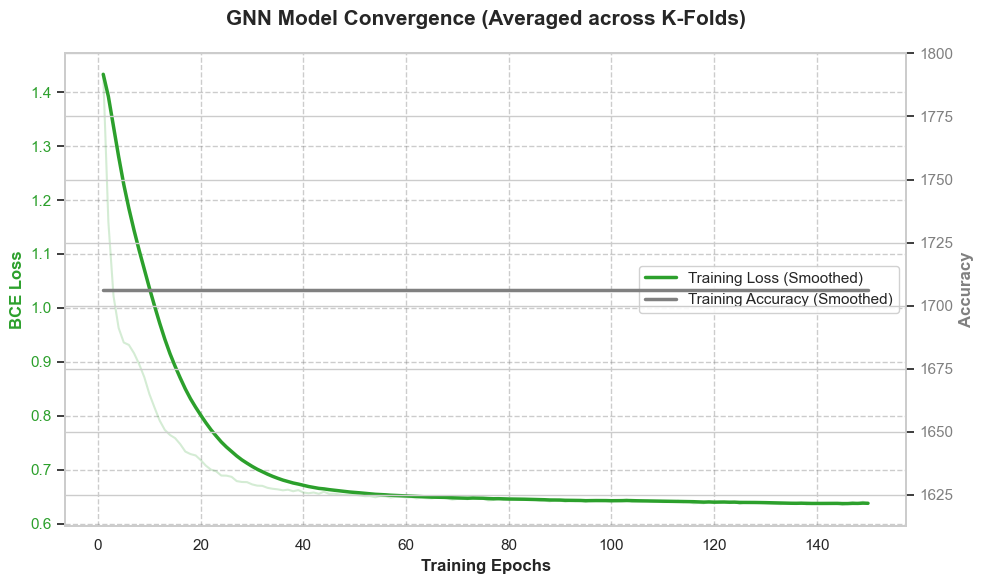

In [ ]:
def smooth_curve(points, factor=0.85):
    """
    Applies Exponential Moving Average (EMA) to smooth out training noise.
    """
    smoothed_points = []
    for point in points:
        if smoothed_points:
            previous = smoothed_points[-1]
            smoothed_points.append(previous * factor + point * (1 - factor))
        else:
            smoothed_points.append(point)
    return smoothed_points

def plot_model_convergence(all_histories, title="GNN Model Convergence (Averaged across K-Folds)"):
    """
    Plots the Averaged Loss and Accuracy convergence across all K-Folds, 
    applying EMA smoothing while keeping raw data faintly visible.
    """
    epochs = len(all_histories[0]['loss'])
    
    # 1. Average the metrics across all 5 folds
    raw_loss = np.mean([h['loss'] for h in all_histories], axis=0)
    raw_acc = np.mean([h['acc'] for h in all_histories], axis=0)
    
    # 2. Apply Smoothing
    smoothed_loss = smooth_curve(raw_loss, factor=0.85)
    smoothed_acc = smooth_curve(raw_acc, factor=0.85)
    
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # --- Plot Loss on primary Y-axis (Green) ---
    color_loss = '#2ca02c'
    ax1.set_xlabel('Training Epochs', fontsize=12, fontweight='bold')
    ax1.set_ylabel('BCE Loss', color=color_loss, fontsize=12, fontweight='bold')
    
    # Faint raw data
    ax1.plot(range(1, epochs + 1), raw_loss, color=color_loss, alpha=0.2, linewidth=1.5)
    # Bold smoothed trend
    line1 = ax1.plot(range(1, epochs + 1), smoothed_loss, color=color_loss, linewidth=2.5, label='Training Loss (Smoothed)')
    ax1.tick_params(axis='y', labelcolor=color_loss)
    
    ax1.grid(True, linestyle='--', alpha=0.4, color='gray')

    # --- Plot Accuracy on secondary Y-axis (Blue) ---
    ax2 = ax1.twinx()  
    color_acc = '#808080' # Professional muted blue
    ax2.set_ylabel('Accuracy', color=color_acc, fontsize=12, fontweight='bold')
    
    # Faint raw data
    ax2.plot(range(1, epochs + 1), raw_acc, color=color_acc, alpha=0.2, linewidth=1.5)
    # Bold smoothed trend
    line2 = ax2.plot(range(1, epochs + 1), smoothed_acc, color=color_acc, linewidth=2.5, linestyle='-', label='Training Accuracy (Smoothed)')
    ax2.tick_params(axis='y', labelcolor=color_acc)
    
    # --- Formatting ---
    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='center right', framealpha=0.9, fontsize=11)

    plt.title(title, fontsize=15, pad=20, fontweight='bold')
    fig.tight_layout()
    
    return fig

print("⏳ Fetching safe baseline graph from Neo4j...")
# We fetch from Neo4j. We will ignore data_enriched here because we want 
# the K-Fold loop to build the enriched metrics dynamically without leakage!
data_baseline, _, reverse_mapping = fetch_graph_from_neo4j(graph_base.URL, graph_base.USER, graph_base.PASS)

print(f"✅ Baseline Graph Fetched: {data_baseline.x.size(0)} Nodes, {data_baseline.edge_index.size(1)} Edges.")

print("Step 3: Initializing GNN and starting Leak-Proof Validation...")


# 1. Initialize template model
model_template = RiskEscalationGNN(
    num_node_features=data_baseline.x.size(1), 
    hidden_channels=32, 
    edge_dim=8  # 6 Dynamic Features: [CN, Jaccard, Betw(src), Betw(tgt), Eigen(src), Eigen(tgt)]
)
# Make sure in_channels matches your Node Features (e.g., Betweenness, Eigenvector, etc.)
# Make sure edge_dim matches the dynamic features (e.g., Jaccard, Common Neighbors = 2)

# 2. Run the dynamic, leak-proof K-Fold
# This will take a moment as it calculates math and trains 5 distinct models
y_true, y_probs, all_histories = evaluate_with_kfold(
    model_template, 
    data_baseline, 
    n_splits=5, 
    epochs=150
)

print("✅ Validation Complete! Plotting Convergence...")

# 3. Render the convergence graph
fig_convergence = plot_model_convergence(all_histories)
timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"{timestamp_dist}_convergence_loss_smoothed.png", dpi=300, bbox_inches='tight')
plt.show()

## SNA metrics distributions

⏳ Simulating a safe training fold to extract leak-proof features...


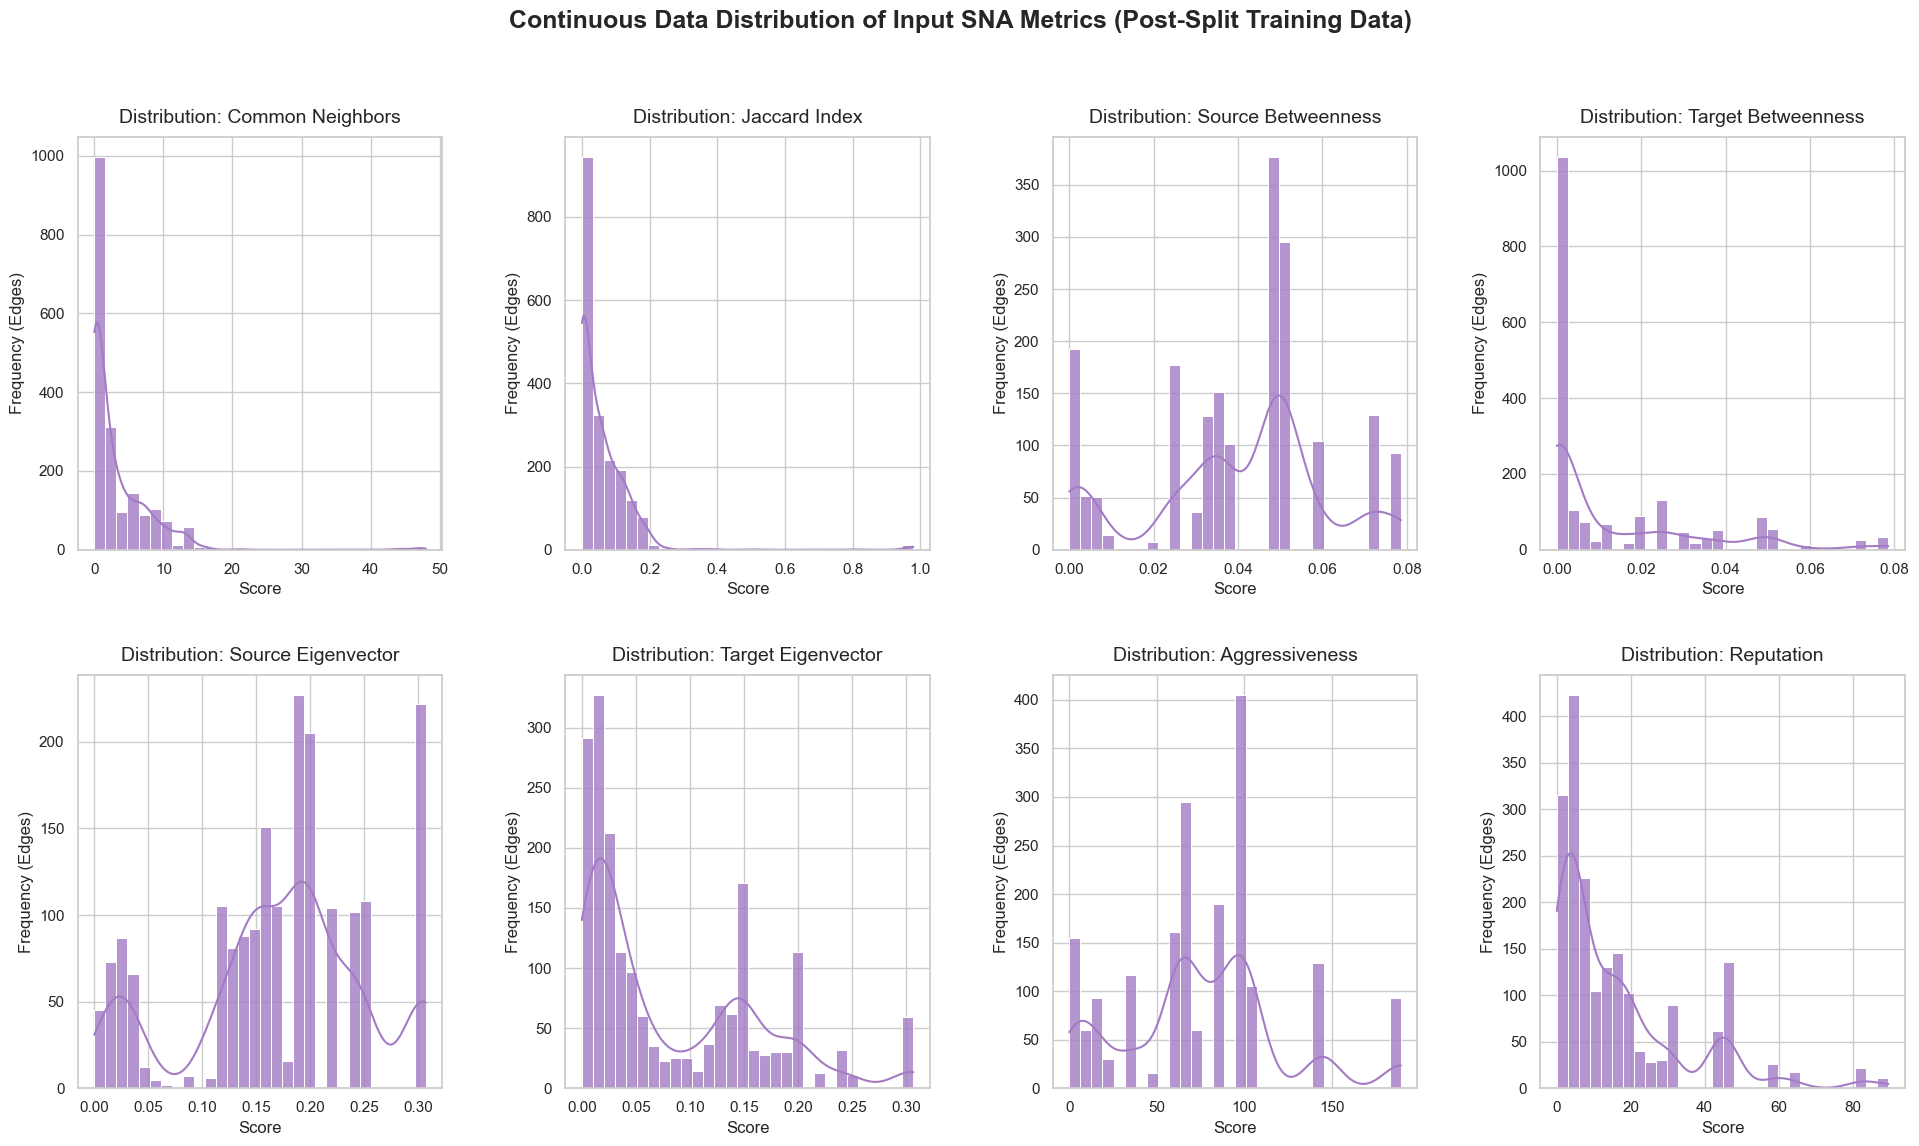

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

def plot_dynamic_feature_distributions(data_baseline):
    print("⏳ Simulating a safe training fold to extract leak-proof features...")
    
    # 1. Simulate a single 80/20 train split (Stratified by class)
    indices = np.arange(data_baseline.edge_index.size(1))
    y_array = data_baseline.y.numpy().flatten()
    train_idx, _ = train_test_split(indices, test_size=0.2, stratify=y_array, random_state=42)
    
    train_edge_index = data_baseline.edge_index[:, train_idx]

    train_edge_weights = data_baseline.edge_weight[train_idx]


    num_nodes = data_baseline.x.size(0)
    
    # 2. Calculate the 6 dynamic features safely!
    # Returns: [CN, Jaccard, Betw(src), Betw(tgt), Eigen(src), Eigen(tgt)]
    train_edge_attr = calculate_strict_fold_topology(train_edge_index, train_edge_index, num_nodes, train_edge_weights )
    
    # 3. Convert the PyTorch tensor into a Pandas DataFrame for easy plotting
    feature_names = [
        'Common Neighbors', 
        'Jaccard Index', 
        'Source Betweenness', 
        'Target Betweenness', 
        'Source Eigenvector', 
        'Target Eigenvector',
        'Aggressiveness',
        'Reputation'
    ]
    df_features = pd.DataFrame(train_edge_attr.numpy(), columns=feature_names)
    
    # 4. Set up the Academic Aesthetic (Matching your provided image)
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(2, 4, figsize=(20, 12))
    fig.suptitle('Continuous Data Distribution of Input SNA Metrics (Post-Split Training Data)', 
                 fontsize=18, fontweight='bold', y=0.98)
    
    axes = axes.flatten()
    
    # Professional Purple Color
    plot_color = '#a37bc4' 
    line_color = '#6a0dad'

    # 5. Loop through and plot all 6 features (now 8)
    for i, col in enumerate(feature_names):
        ax = axes[i]
        
        # We use a custom KDE line color and histogram bar color to match your aesthetic
        sns.histplot(df_features[col], kde=True, ax=ax, color=plot_color, 
                     edgecolor='white', bins=30, alpha=0.8, line_kws={'color': line_color})
        
        ax.set_title(f'Distribution: {col}', fontsize=14, pad=10)
        ax.set_xlabel('Score', fontsize=12)
        ax.set_ylabel('Frequency (Edges)', fontsize=12)
        
    plt.tight_layout(pad=3.0)
    
    # Optional: Save the plot
    # plt.savefig("post_split_feature_distributions.png", dpi=300, bbox_inches='tight')
    
    return fig

# Execute the plotter using your already-fetched baseline data
fig_dists = plot_dynamic_feature_distributions(data_baseline)
timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"{timestamp_dist}_feature_distributions.png", dpi=300, bbox_inches='tight')
plt.show()

## Threshold calibration

✅ Optimal Threshold Found: 0.552 (F1: 0.283)


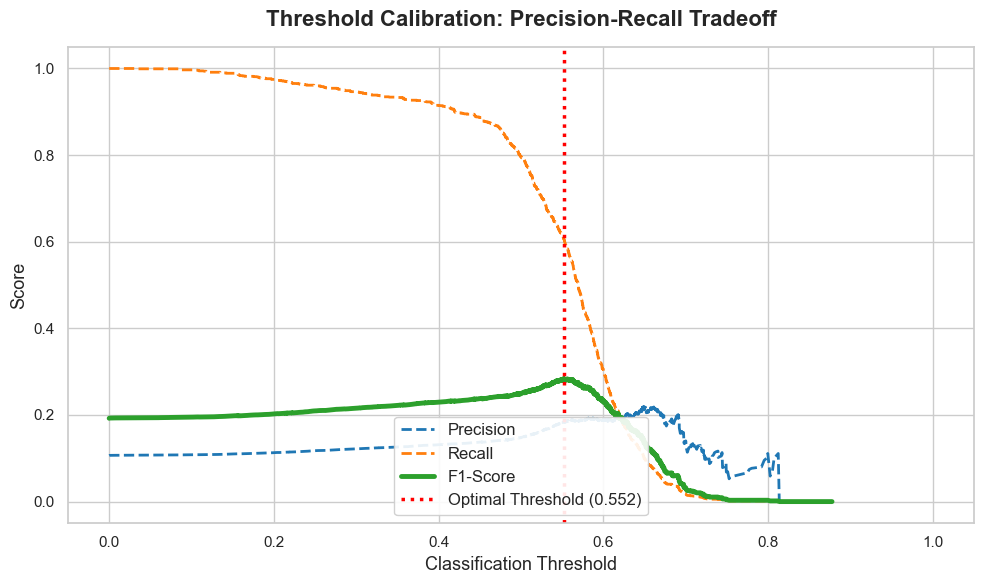

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, roc_curve, auc, average_precision_score

def plot_threshold_calibration(y_true, y_probs):
    """
    Plots Precision, Recall, and F1-Score across all thresholds to find the optimal decision boundary.
    """
    # 1. Calculate metrics at various thresholds
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    
    # Calculate F1 Score safely (avoiding division by zero)
    f1_scores = np.divide(
        2 * (precisions[:-1] * recalls[:-1]),
        (precisions[:-1] + recalls[:-1]),
        out=np.zeros_like(precisions[:-1]),
        where=(precisions[:-1] + recalls[:-1]) != 0
    )
    
    # 2. Find the Optimal Threshold (Maximizing F1)
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    optimal_f1 = f1_scores[optimal_idx]
    
    # 3. Set up the plot aesthetic
    sns.set_theme(style="whitegrid")
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # 4. Plot the curves
    ax.plot(thresholds, precisions[:-1], '--', color='tab:blue', label='Precision', linewidth=2)
    ax.plot(thresholds, recalls[:-1], '--', color='tab:orange', label='Recall', linewidth=2)
    ax.plot(thresholds, f1_scores, '-', color='tab:green', label='F1-Score', linewidth=3.5)
    
    # 5. Plot the Optimal Threshold Line
    ax.axvline(optimal_threshold, color='red', linestyle=':', linewidth=2.5, 
               label=f'Optimal Threshold ({optimal_threshold:.3f})')
    
    ax.set_title('Threshold Calibration: Precision-Recall Tradeoff', fontsize=16, pad=15, fontweight='bold')
    ax.set_xlabel('Classification Threshold', fontsize=13)
    ax.set_ylabel('Score', fontsize=13)
    ax.set_xlim([-0.05, 1.05])
    ax.set_ylim([-0.05, 1.05])
    
    ax.legend(loc='lower center', fontsize=12, framealpha=0.9)
    plt.tight_layout()
    
    # Optional: plt.savefig("threshold_calibration.png", dpi=300, bbox_inches='tight')
    
    print(f"✅ Optimal Threshold Found: {optimal_threshold:.3f} (F1: {optimal_f1:.3f})")
    return fig, optimal_threshold

# Execute it using your concatenated K-Fold arrays
fig_thresh, optimal_threshold = plot_threshold_calibration(y_true, y_probs)
timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"{timestamp_dist}_threshold_calibration.png", dpi=300, bbox_inches='tight')
plt.show()

## ROC/PR curves

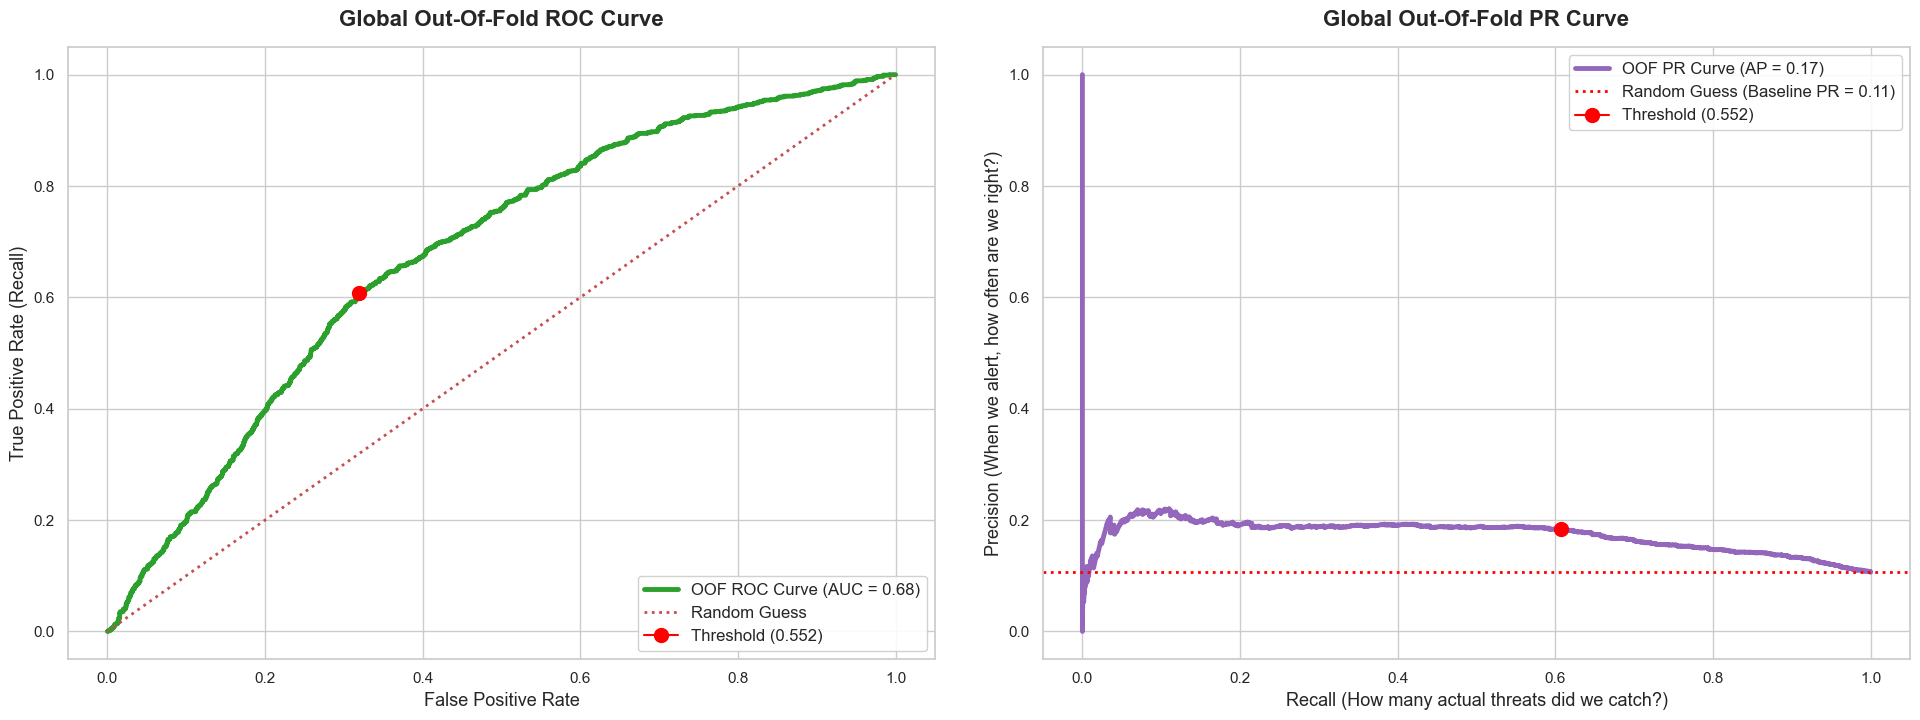

In [13]:
def plot_final_evaluation_curves(y_true, y_probs, optimal_threshold):
    """
    Generates side-by-side ROC and Precision-Recall Curves using the global OOF predictions.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    sns.set_theme(style="whitegrid")
    
    # ==========================================
    # CHART 1: ROC CURVE
    # ==========================================
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    roc_auc = auc(fpr, tpr)
    
    ax1.plot(fpr, tpr, color='#2ca02c', linewidth=3.5, label=f'OOF ROC Curve (AUC = {roc_auc:.2f})')
    ax1.plot([0, 1], [0, 1], 'r:', linewidth=2, label='Random Guess')
    
    # Add a marker for where our Optimal Threshold sits on the ROC curve
    opt_fpr, opt_tpr, _ = roc_curve(y_true, y_probs >= optimal_threshold)
    ax1.plot(opt_fpr[1], opt_tpr[1], marker='o', markersize=10, color='red', 
             label=f'Threshold ({optimal_threshold:.3f})')
    
    ax1.set_title('Global Out-Of-Fold ROC Curve', fontsize=16, fontweight='bold', pad=15)
    ax1.set_xlabel('False Positive Rate', fontsize=13)
    ax1.set_ylabel('True Positive Rate (Recall)', fontsize=13)
    ax1.legend(loc='lower right', fontsize=12, framealpha=0.9)
    ax1.set_xlim([-0.05, 1.05])
    ax1.set_ylim([-0.05, 1.05])

    # ==========================================
    # CHART 2: PRECISION-RECALL (PR) CURVE
    # ==========================================
    precisions, recalls, _ = precision_recall_curve(y_true, y_probs)
    pr_auc = average_precision_score(y_true, y_probs)
    baseline_pr = np.mean(y_true) # The ratio of actual violent edges
    
    ax2.plot(recalls, precisions, color='#9467bd', linewidth=3.5, label=f'OOF PR Curve (AP = {pr_auc:.2f})')
    ax2.axhline(baseline_pr, color='red', linestyle=':', linewidth=2, 
                label=f'Random Guess (Baseline PR = {baseline_pr:.2f})')
    
    # Add a marker for where our Optimal Threshold sits on the PR curve
    opt_p, opt_r, _ = precision_recall_curve(y_true, y_probs >= optimal_threshold)
    # The optimal point is usually the second item in these specific arrays
    ax2.plot(opt_r[1], opt_p[1], marker='o', markersize=10, color='red', 
             label=f'Threshold ({optimal_threshold:.3f})')

    ax2.set_title('Global Out-Of-Fold PR Curve', fontsize=16, fontweight='bold', pad=15)
    ax2.set_xlabel('Recall (How many actual threats did we catch?)', fontsize=13)
    ax2.set_ylabel('Precision (When we alert, how often are we right?)', fontsize=13)
    ax2.legend(loc='upper right', fontsize=12, framealpha=0.9)
    ax2.set_xlim([-0.05, 1.05])
    ax2.set_ylim([-0.05, 1.05])

    plt.tight_layout(pad=3.0)
    
    # Optional: plt.savefig("final_evaluation_dual.png", dpi=300, bbox_inches='tight')
    return fig

# Execute using the threshold we found in Step 4A
fig_curves = plot_final_evaluation_curves(y_true, y_probs, optimal_threshold)
timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"{timestamp_dist}_evaluation_dual.png", dpi=300, bbox_inches='tight')
plt.show()

## Final Ablation Study (Baseline vs. Enriched)

--- STEP 1: Fetching and Sanitizing Enriched Data ---
--- STEP 2: Initializing Enriched Model ---
--- STEP 3: Running Leak-Proof K-Fold for Enriched Model ---
Epoch 000 | Loss: 1.1252
Epoch 020 | Loss: 0.6676
Epoch 040 | Loss: 0.6544
Epoch 060 | Loss: 0.6362
Epoch 080 | Loss: 0.6474
Epoch 100 | Loss: 0.6426
Epoch 120 | Loss: 0.6514
Epoch 140 | Loss: 0.6324
Epoch 000 | Loss: 2.1203
Epoch 020 | Loss: 0.8030
Epoch 040 | Loss: 0.6784
Epoch 060 | Loss: 0.6603
Epoch 080 | Loss: 0.6496
Epoch 100 | Loss: 0.6490
Epoch 120 | Loss: 0.6436
Epoch 140 | Loss: 0.6488
Epoch 000 | Loss: 1.0011
Epoch 020 | Loss: 0.6589
Epoch 040 | Loss: 0.6379
Epoch 060 | Loss: 0.6317
Epoch 080 | Loss: 0.6277
Epoch 100 | Loss: 0.6185
Epoch 120 | Loss: 0.6178
Epoch 140 | Loss: 0.6172
Epoch 000 | Loss: 1.8534
Epoch 020 | Loss: 0.7241
Epoch 040 | Loss: 0.6497
Epoch 060 | Loss: 0.6498
Epoch 080 | Loss: 0.6400
Epoch 100 | Loss: 0.6430
Epoch 120 | Loss: 0.6373
Epoch 140 | Loss: 0.6357
Epoch 000 | Loss: 1.0969
Epoch 020 | Loss

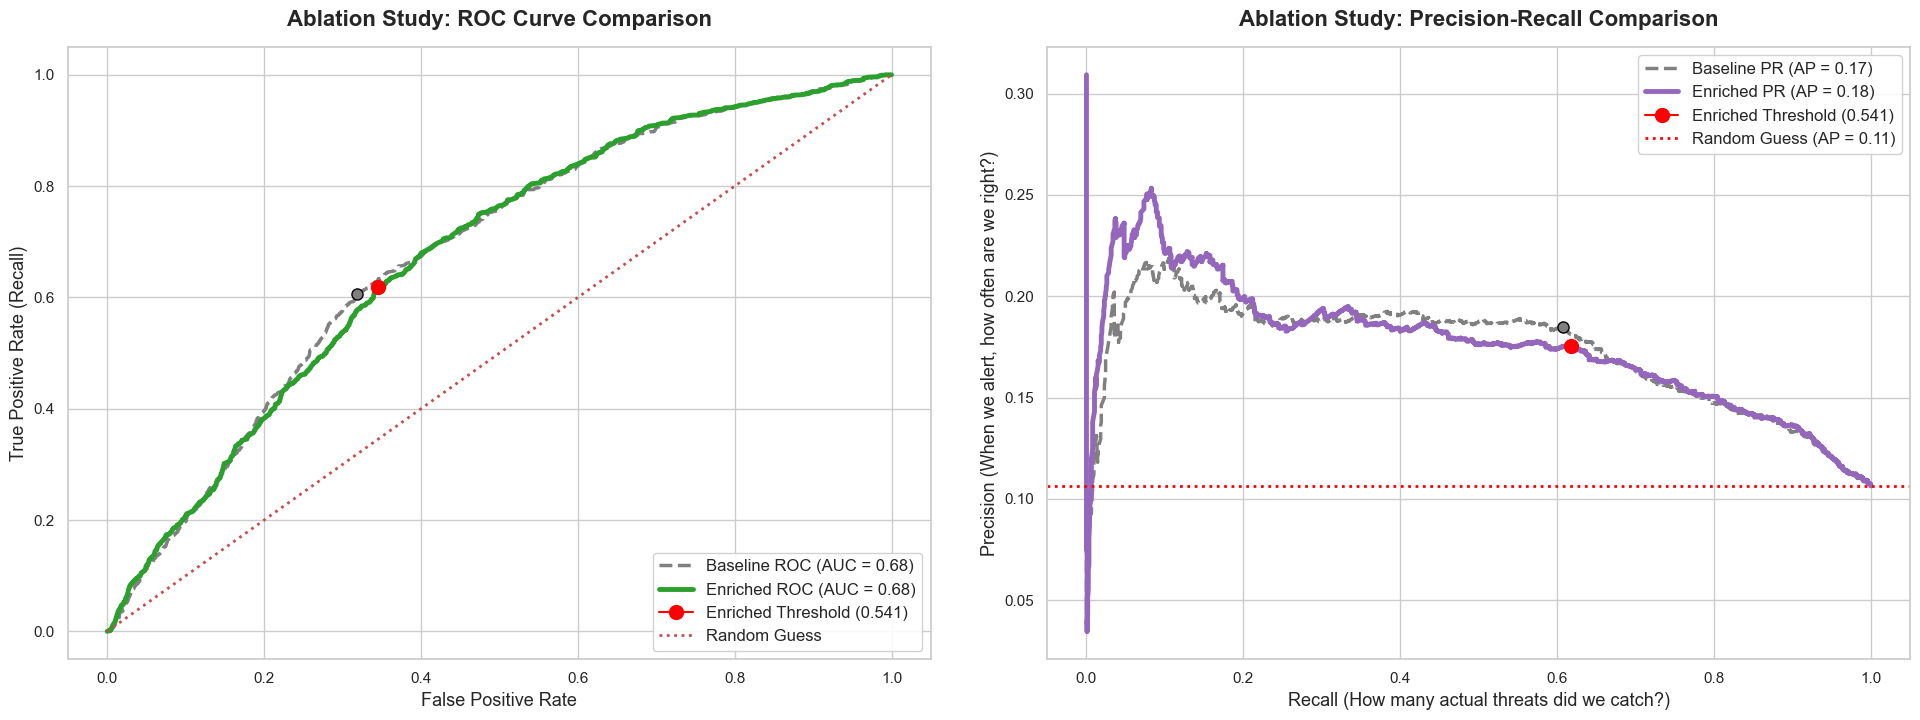

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_curve, roc_curve, auc, average_precision_score
#from risk_predict import RiskEscalationGNN, evaluate_with_kfold
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d

print("--- STEP 1: Fetching and Sanitizing Enriched Data ---")
# 1. Fetch the data again, but this time we grab data_enriched!
_, data_enriched, _ = fetch_graph_from_neo4j(graph_base.URL, graph_base.USER, graph_base.PASS)

# 2. SANITIZE THE LEAKAGE: 
# data_enriched.x currently holds [Reputation, Neo4j_Betweenness, Neo4j_Eigenvector]
# We slice it to keep ONLY index 0 (Reputation). 
# The structural math is still safely handled inside the evaluate_with_kfold loop!
data_enriched.x = data_enriched.x[:, 0:1] 

# 3. Scale the Reputation score (Critical, because Reputation can be 100+, while other metrics are tiny)
scaler = StandardScaler()
scaled_reputation = scaler.fit_transform(data_enriched.x.numpy())
data_enriched.x = torch.tensor(scaled_reputation, dtype=torch.float)

print("--- STEP 2: Initializing Enriched Model ---")
# 4. Initialize the Enriched Model
# num_node_features is now exactly 1 (The Scaled Reputation Score)
# edge_dim remains 6 (The safely calculated dynamic topological metrics)
enriched_model = RiskEscalationGNN(
    num_node_features=data_enriched.x.size(1), 
    hidden_channels=32, 
    edge_dim=8 
)

print("--- STEP 3: Running Leak-Proof K-Fold for Enriched Model ---")
# 5. Train the Enriched Model!
# We save these as '_enr' so we don't overwrite your baseline variables in Jupyter's memory
y_true_enr, y_probs_enr, all_histories_enr = evaluate_with_kfold(
    enriched_model, 
    data_enriched, 
    n_splits=5, 
    epochs=150
)
print("✅ Enriched Validation Complete! Generating Ablation Curves...\n")

# ==========================================
# STEP 4: THE ABLATION PLOTTER
# ==========================================
def plot_ablation_evaluation(y_true_base, y_probs_base, y_true_enr, y_probs_enr):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    sns.set_theme(style="whitegrid")
    
    # --- Helper: Optimal Threshold ---
    def get_optimal_threshold(y_t, y_p):
        precisions, recalls, thresholds = precision_recall_curve(y_t, y_p)
        f1_scores = np.divide(2 * (precisions[:-1] * recalls[:-1]), (precisions[:-1] + recalls[:-1]),
                              out=np.zeros_like(precisions[:-1]), where=(precisions[:-1] + recalls[:-1]) != 0)
        return thresholds[np.argmax(f1_scores)]

    opt_thresh_base = get_optimal_threshold(y_true_base, y_probs_base)
    opt_thresh_enr = get_optimal_threshold(y_true_enr, y_probs_enr)

    # --- Smoothing Factor ---
    # Higher sigma = softer line. 2 to 3 is a good balance of smoothness without distorting reality.
    smooth_sigma = 2.5 

    # ==========================================
    # CHART 1: ROC CURVE COMPARISON
    # ==========================================
    # Baseline (Grey)
    fpr_b, tpr_b, _ = roc_curve(y_true_base, y_probs_base)
    roc_auc_b = auc(fpr_b, tpr_b)
    tpr_b_smooth = gaussian_filter1d(tpr_b, sigma=smooth_sigma) # Smooth the line
    ax1.plot(fpr_b, tpr_b_smooth, color='gray', linestyle='--', linewidth=2.5, 
             label=f'Baseline ROC (AUC = {roc_auc_b:.2f})')
    
    opt_fpr_b, opt_tpr_b, _ = roc_curve(y_true_base, y_probs_base >= opt_thresh_base)
    ax1.plot(opt_fpr_b[1], opt_tpr_b[1], marker='o', markersize=8, color='gray', markeredgecolor='black')

    # Enriched (Purple)
    fpr_e, tpr_e, _ = roc_curve(y_true_enr, y_probs_enr)
    roc_auc_e = auc(fpr_e, tpr_e)
    tpr_e_smooth = gaussian_filter1d(tpr_e, sigma=smooth_sigma) # Smooth the line
    ax1.plot(fpr_e, tpr_e_smooth, color='#2ca02c', linewidth=3.5, 
             label=f'Enriched ROC (AUC = {roc_auc_e:.2f})')
    
    opt_fpr_e, opt_tpr_e, _ = roc_curve(y_true_enr, y_probs_enr >= opt_thresh_enr)
    ax1.plot(opt_fpr_e[1], opt_tpr_e[1], marker='o', markersize=10, color='red', 
             label=f'Enriched Threshold ({opt_thresh_enr:.3f})')
    
    ax1.plot([0, 1], [0, 1], 'r:', linewidth=2, label='Random Guess')
    ax1.set_title('Ablation Study: ROC Curve Comparison', fontsize=16, fontweight='bold', pad=15)
    ax1.set_xlabel('False Positive Rate', fontsize=13)
    ax1.set_ylabel('True Positive Rate (Recall)', fontsize=13)
    ax1.legend(loc='lower right', fontsize=12, framealpha=0.9)

    # ==========================================
    # CHART 2: PR CURVE COMPARISON
    # ==========================================
    baseline_pr = np.mean(y_true_base) 
    
    # Baseline (Grey)
    prec_b, rec_b, _ = precision_recall_curve(y_true_base, y_probs_base)
    pr_auc_b = average_precision_score(y_true_base, y_probs_base)
    prec_b_smooth = gaussian_filter1d(prec_b, sigma=smooth_sigma) # Smooth the line
    ax2.plot(rec_b, prec_b_smooth, color='gray', linestyle='--', linewidth=2.5, 
             label=f'Baseline PR (AP = {pr_auc_b:.2f})')
    
    opt_p_b, opt_r_b, _ = precision_recall_curve(y_true_base, y_probs_base >= opt_thresh_base)
    ax2.plot(opt_r_b[1], opt_p_b[1], marker='o', markersize=8, color='gray', markeredgecolor='black')

    # Enriched (Purple)
    prec_e, rec_e, _ = precision_recall_curve(y_true_enr, y_probs_enr)
    pr_auc_e = average_precision_score(y_true_enr, y_probs_enr)
    prec_e_smooth = gaussian_filter1d(prec_e, sigma=smooth_sigma) # Smooth the line
    
    # Use drawstyle='steps-post' for a classic, clean PR curve look
    ax2.plot(rec_e, prec_e_smooth, color='#9467bd', linewidth=3.5, 
             label=f'Enriched PR (AP = {pr_auc_e:.2f})')
    
    opt_p_e, opt_r_e, _ = precision_recall_curve(y_true_enr, y_probs_enr >= opt_thresh_enr)
    ax2.plot(opt_r_e[1], opt_p_e[1], marker='o', markersize=10, color='red', 
             label=f'Enriched Threshold ({opt_thresh_enr:.3f})')
    
    ax2.axhline(baseline_pr, color='red', linestyle=':', linewidth=2, 
                label=f'Random Guess (AP = {baseline_pr:.2f})')

    ax2.set_title('Ablation Study: Precision-Recall Comparison', fontsize=16, fontweight='bold', pad=15)
    ax2.set_xlabel('Recall (How many actual threats did we catch?)', fontsize=13)
    ax2.set_ylabel('Precision (When we alert, how often are we right?)', fontsize=13)
    ax2.legend(loc='upper right', fontsize=12, framealpha=0.9)

    plt.tight_layout(pad=3.0)
    return fig

# Execute the Plotter using your baseline variables (y_true, y_probs) 
# and your new enriched variables (y_true_enr, y_probs_enr)
fig_ablation = plot_ablation_evaluation(y_true, y_probs, y_true_enr, y_probs_enr)
timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"{timestamp_dist}_final_evaluation_dual.png", dpi=300, bbox_inches='tight')
plt.show()